In [1]:
from google.colab import files

uploaded = files.upload()

Saving engine_data_clean.csv to engine_data_clean.csv
Saving carOBD_clean.csv to carOBD_clean.csv


In [2]:

import pandas as pd

engine = pd.read_csv("/content/engine_data_clean.csv")
obd = pd.read_csv("/content/carOBD_clean.csv")

datasets = {
    "Engine Health Dataset": engine,
    "OBD-II Dataset": obd
}

for name, df in datasets.items():
    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nMissing values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nNumeric summary:")
    display(df.describe().T)

print("\nEngine condition labels:")
print(engine["engine_condition"].value_counts(dropna=False))

print("\nCoolant extreme labels:")
print(engine["coolant_temp_extreme"].value_counts(dropna=False))



Engine Health Dataset
Shape: (19535, 8)

Columns:
['engine_rpm', 'lub_oil_pressure', 'fuel_pressure', 'coolant_pressure', 'lub_oil_temp', 'coolant_temp', 'engine_condition', 'coolant_temp_extreme']

Missing values:
Series([], dtype: int64)

Duplicate rows: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
engine_rpm,19535.0,791.239263,267.611193,61.000000,593.000000,746.000000,934.000000,2239.000000
lub_oil_pressure,19535.0,3.303775,1.021643,0.003384,2.518815,3.162035,4.055272,7.265566
fuel_pressure,19535.0,6.655615,2.761021,0.003187,4.916886,6.201720,7.744973,21.138326
coolant_pressure,19535.0,2.335369,1.036382,0.002483,1.600466,2.166883,2.848840,7.478505
lub_oil_temp,19535.0,77.643420,3.110984,71.321974,75.725990,76.817350,78.071691,89.580796
coolant_temp,19535.0,78.427433,6.206749,61.673325,73.895421,78.346662,82.915411,195.527912
engine_condition,19535.0,0.630509,0.482679,0.000000,0.000000,1.000000,1.000000,1.000000
coolant_temp_extreme,19535.0,0.000102,0.010118,0.000000,0.000000,0.000000,0.000000,1.000000



OBD-II Dataset
Shape: (274968, 26)

Columns:
['engine_run_time', 'engine_rpm', 'vehicle_speed', 'throttle', 'engine_load', 'coolant_temperature', 'long_term_fuel_trim_bank_1', 'short_term_fuel_trim_bank_1', 'intake_manifold_pressure', 'fuel_tank', 'absolute_throttle_b', 'pedal_d', 'pedal_e', 'commanded_throttle_actuator', 'absolute_barometric_pressure', 'relative_throttle_position', 'intake_air_temp', 'timing_advance', 'catalyst_temperature_bank1_sensor1', 'catalyst_temperature_bank1_sensor2', 'control_module_voltage', 'commanded_evaporative_purge', 'time_since_trouble_codes_cleared', 'warm_ups_since_codes_cleared', 'source_file', 'operating_mode']

Missing values:
time_since_trouble_codes_cleared    2111
warm_ups_since_codes_cleared        2111
dtype: int64

Duplicate rows: 0

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
engine_run_time,274968.0,753.191626,611.291219,0.000000,293.000000,605.000000,1054.000000,3696.000000
engine_rpm,274968.0,1218.856800,488.437078,0.000000,813.250000,1122.500000,1578.750000,3768.750000
vehicle_speed,274968.0,22.924097,22.081302,0.000000,0.000000,21.000000,38.000000,127.000000
throttle,274968.0,19.255917,3.770289,13.333000,16.471000,18.823530,20.392157,78.823532
engine_load,274968.0,35.004000,14.763357,0.000000,25.490196,30.196079,38.823528,100.000000
coolant_temperature,274968.0,83.137445,11.157926,21.000000,86.000000,87.000000,88.000000,96.000000
long_term_fuel_trim_bank_1,274968.0,-0.462844,2.248675,-8.593750,-1.562500,-0.781250,0.781250,7.031200
short_term_fuel_trim_bank_1,274968.0,-0.059913,3.554728,-20.312500,-2.343750,0.000000,2.343750,19.531250
intake_manifold_pressure,274968.0,35.657000,15.103624,16.000000,26.000000,31.000000,40.000000,102.000000
fuel_tank,274968.0,47.166153,20.352610,0.000000,29.411764,43.921570,61.960785,90.980392



Engine condition labels:
engine_condition
1    12317
0     7218
Name: count, dtype: int64

Coolant extreme labels:
coolant_temp_extreme
0    19533
1        2
Name: count, dtype: int64


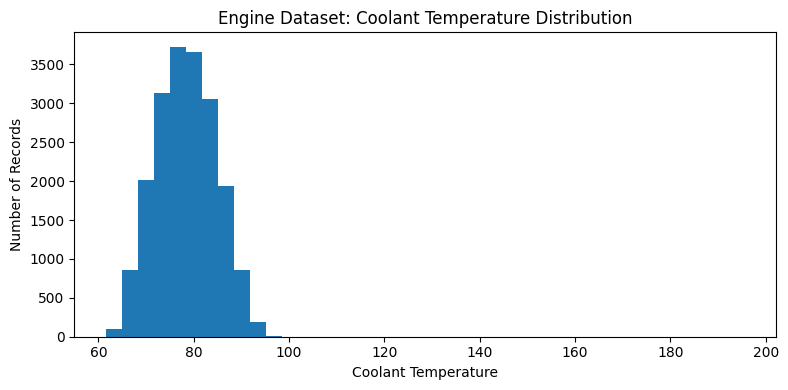

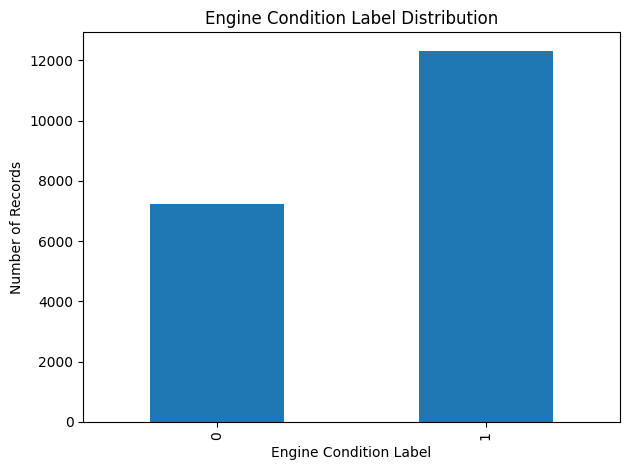

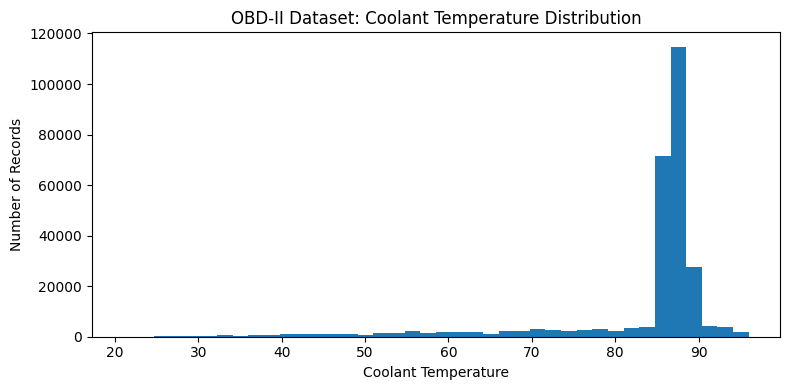

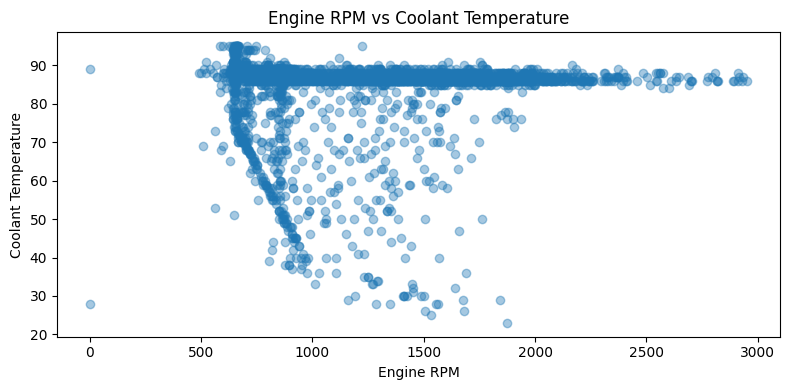

In [3]:

import matplotlib.pyplot as plt

# 1. Coolant temperature distribution
plt.figure(figsize=(8, 4))
plt.hist(engine["coolant_temp"], bins=40)
plt.xlabel("Coolant Temperature")
plt.ylabel("Number of Records")
plt.title("Engine Dataset: Coolant Temperature Distribution")
plt.tight_layout()
plt.show()

# 2. Engine condition distribution
engine["engine_condition"].value_counts().sort_index().plot(
    kind="bar"
)
plt.xlabel("Engine Condition Label")
plt.ylabel("Number of Records")
plt.title("Engine Condition Label Distribution")
plt.tight_layout()
plt.show()

# 3. OBD-II coolant temperature distribution
plt.figure(figsize=(8, 4))
plt.hist(obd["coolant_temperature"], bins=40)
plt.xlabel("Coolant Temperature")
plt.ylabel("Number of Records")
plt.title("OBD-II Dataset: Coolant Temperature Distribution")
plt.tight_layout()
plt.show()

# 4. RPM vs coolant temperature
plt.figure(figsize=(8, 4))
plt.scatter(
    obd["engine_rpm"].sample(
        min(3000, len(obd)), random_state=42
    ),
    obd["coolant_temperature"].sample(
        min(3000, len(obd)), random_state=42
    ),
    alpha=0.4
)
plt.xlabel("Engine RPM")
plt.ylabel("Coolant Temperature")
plt.title("Engine RPM vs Coolant Temperature")
plt.tight_layout()
plt.show()


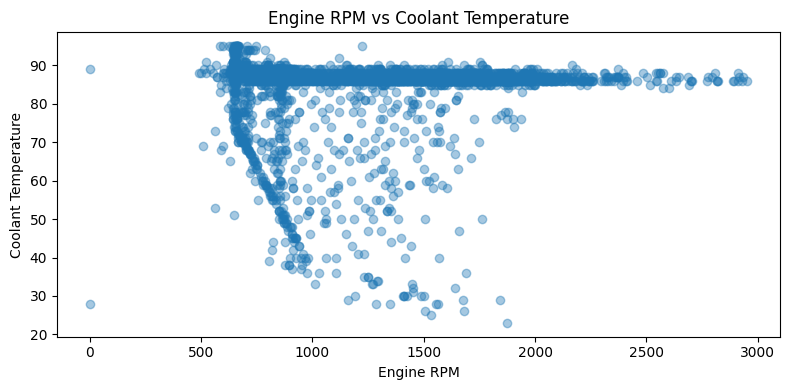

In [5]:

sample = obd.sample(min(3000, len(obd)), random_state=42)

plt.figure(figsize=(8, 4))
plt.scatter(
    sample["engine_rpm"],
    sample["coolant_temperature"],
    alpha=0.4
)
plt.xlabel("Engine RPM")
plt.ylabel("Coolant Temperature")
plt.title("Engine RPM vs Coolant Temperature")
plt.tight_layout()
plt.show()


In [7]:
import pandas as pd

engine = pd.read_csv("/content/engine_data_clean.csv")

print(
    engine.groupby("engine_condition")[
        [
            "engine_rpm",
            "lub_oil_pressure",
            "fuel_pressure",
            "coolant_pressure",
            "lub_oil_temp",
            "coolant_temp"
        ]
    ].mean().round(2)
)

print("\nMedian sensor readings by class:")
print(
    engine.groupby("engine_condition")[
        [
            "engine_rpm",
            "lub_oil_pressure",
            "coolant_pressure",
            "lub_oil_temp",
            "coolant_temp"
        ]
    ].median().round(2)
)

                  engine_rpm  lub_oil_pressure  fuel_pressure  \
engine_condition                                                
0                      885.0              3.22           6.24   
1                      736.3              3.35           6.90   

                  coolant_pressure  lub_oil_temp  coolant_temp  
engine_condition                                                
0                             2.37         78.02         78.80  
1                             2.32         77.42         78.21  

Median sensor readings by class:
                  engine_rpm  lub_oil_pressure  coolant_pressure  \
engine_condition                                                   
0                      843.0              3.07              2.18   
1                      690.0              3.21              2.16   

                  lub_oil_temp  coolant_temp  
engine_condition                              
0                        77.09         78.77  
1                        76.66 

In [8]:

print(
    engine.loc[
        engine["coolant_temp_extreme"] == 1
    ].to_string(index=False)
)

print("\nCoolant temperature range:")
print(engine["coolant_temp"].describe())

print("\nCoolant temperature extremes:")
print(
    engine.sort_values("coolant_temp")[
        ["engine_rpm", "coolant_temp", "coolant_temp_extreme"]
    ].head(10)
)

print(
    engine.sort_values("coolant_temp", ascending=False)[
        ["engine_rpm", "coolant_temp", "coolant_temp_extreme"]
    ].head(10)
)


 engine_rpm  lub_oil_pressure  fuel_pressure  coolant_pressure  lub_oil_temp  coolant_temp  engine_condition  coolant_temp_extreme
        455          2.010802       7.806127          1.619575     76.519385    195.527912                 1                     1
        760          4.908028       2.594570          1.747730     77.873482    118.371957                 0                     1

Coolant temperature range:
count    19535.000000
mean        78.427433
std          6.206749
min         61.673325
25%         73.895421
50%         78.346662
75%         82.915411
max        195.527912
Name: coolant_temp, dtype: float64

Coolant temperature extremes:
       engine_rpm  coolant_temp  coolant_temp_extreme
10761         379     61.673325                     0
4496          579     62.445955                     0
4563          720     63.056066                     0
12542         587     63.086903                     0
5870          933     63.124119                     0
5060         

In [9]:

obd = pd.read_csv("/content/carOBD_clean.csv")

print("Available OBD-II columns:")
for col in obd.columns:
    print(col)

print("\nMissing values:")
print(obd.isnull().sum().sort_values(ascending=False).head(15))


Available OBD-II columns:
engine_run_time
engine_rpm
vehicle_speed
throttle
engine_load
coolant_temperature
long_term_fuel_trim_bank_1
short_term_fuel_trim_bank_1
intake_manifold_pressure
fuel_tank
absolute_throttle_b
pedal_d
pedal_e
commanded_throttle_actuator
absolute_barometric_pressure
relative_throttle_position
intake_air_temp
timing_advance
catalyst_temperature_bank1_sensor1
catalyst_temperature_bank1_sensor2
control_module_voltage
commanded_evaporative_purge
time_since_trouble_codes_cleared
warm_ups_since_codes_cleared
source_file
operating_mode

Missing values:
warm_ups_since_codes_cleared        2111
time_since_trouble_codes_cleared    2111
vehicle_speed                          0
throttle                               0
engine_load                            0
coolant_temperature                    0
long_term_fuel_trim_bank_1             0
short_term_fuel_trim_bank_1            0
engine_run_time                        0
engine_rpm                             0
fuel_tank     

In [10]:
print(engine["lub_oil_pressure"].describe())
print(engine["lub_oil_pressure"].sort_values().head(10))
print(engine["lub_oil_pressure"].sort_values(ascending=False).head(10))

count    19535.000000
mean         3.303775
std          1.021643
min          0.003384
25%          2.518815
50%          3.162035
75%          4.055272
max          7.265566
Name: lub_oil_pressure, dtype: float64
11049    0.003384
2159     0.004214
3390     0.007891
15542    0.012157
1117     0.013606
1569     0.014064
6031     0.017449
2144     0.018663
5722     0.025207
1101     0.027071
Name: lub_oil_pressure, dtype: float64
655      7.265566
3155     7.051322
12482    6.826921
15303    6.729324
15719    6.681497
8217     6.668046
17612    6.659097
5700     6.643938
10602    6.615159
18336    6.575457
Name: lub_oil_pressure, dtype: float64


In [11]:

import pandas as pd

engine = pd.read_csv("/content/engine_data_clean.csv")

# Inspect the 20 records with the lowest oil pressure
cols = [
    "engine_rpm",
    "lub_oil_pressure",
    "fuel_pressure",
    "coolant_pressure",
    "lub_oil_temp",
    "coolant_temp",
    "engine_condition"
]

lowest_pressure = engine.nsmallest(20, "lub_oil_pressure")

display(lowest_pressure[cols])

# Compare the lowest and highest oil-pressure groups
engine["pressure_group"] = pd.qcut(
    engine["lub_oil_pressure"],
    q=4,
    labels=["Lowest 25%", "Lower-middle",
            "Upper-middle", "Highest 25%"]
)

print(
    engine.groupby("pressure_group", observed=True)[
        ["engine_rpm", "lub_oil_pressure",
         "lub_oil_temp", "coolant_temp",
         "engine_condition"]
    ].mean().round(3)
)


,engine_rpm,lub_oil_pressure,fuel_pressure,coolant_pressure,lub_oil_temp,coolant_temp,engine_condition
11049,392,0.003384,5.385947,1.505216,73.660278,81.266458,1
2159,509,0.004214,5.545596,1.128094,78.685646,71.177109,1
3390,825,0.007891,6.157039,2.881308,84.747761,77.484463,0
15542,606,0.012157,6.928875,2.592572,74.376574,67.599133,1
1117,1021,0.013606,6.374758,1.912457,76.360571,76.523517,0
1569,1411,0.014064,6.927239,2.167352,78.109378,82.263142,1
6031,454,0.017449,7.234137,1.275377,80.558970,67.932096,1
2144,1116,0.018663,8.583007,2.720964,76.899266,81.692694,1
5722,918,0.025207,8.142067,2.268656,76.745596,89.747536,0
1101,1179,0.027071,5.883258,2.448413,75.945565,75.960373,0


                engine_rpm  lub_oil_pressure  lub_oil_temp  coolant_temp  \
pressure_group                                                             
Lowest 25%         782.090             2.099        77.661        79.209   
Lower-middle       788.151             2.822        77.623        78.216   
Upper-middle       794.229             3.614        77.649        78.191   
Highest 25%        800.489             4.680        77.641        78.093   

                engine_condition  
pressure_group                    
Lowest 25%                 0.575  
Lower-middle               0.646  
Upper-middle               0.643  
Highest 25%                0.658  


In [12]:

import pandas as pd

engine = pd.read_csv("/content/engine_data_clean.csv")

# Check the distribution and repeated values
print("Oil pressure statistics:")
print(engine["lub_oil_pressure"].describe())

print("\nOil pressure quantiles:")
print(
    engine["lub_oil_pressure"].quantile(
        [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
    )
)

# Inspect the lowest 50 readings
cols = [
    "engine_rpm",
    "lub_oil_pressure",
    "lub_oil_temp",
    "coolant_temp",
    "engine_condition"
]

display(
    engine.nsmallest(50, "lub_oil_pressure")[cols]
)

# Compare pressure and label distributions
print("\nOil pressure by engine condition:")
print(
    engine.groupby("engine_condition")["lub_oil_pressure"]
    .agg(["count", "min", "median", "mean", "max"])
    .round(4)
)


Oil pressure statistics:
count    19535.000000
mean         3.303775
std          1.021643
min          0.003384
25%          2.518815
50%          3.162035
75%          4.055272
max          7.265566
Name: lub_oil_pressure, dtype: float64

Oil pressure quantiles:
0.00    0.003384
0.01    0.858308
0.05    1.941852
0.25    2.518815
0.50    3.162035
0.75    4.055272
0.95    5.058040
0.99    5.597022
1.00    7.265566
Name: lub_oil_pressure, dtype: float64


,engine_rpm,lub_oil_pressure,lub_oil_temp,coolant_temp,engine_condition
11049,392,0.003384,73.660278,81.266458,1
2159,509,0.004214,78.685646,71.177109,1
3390,825,0.007891,84.747761,77.484463,0
15542,606,0.012157,74.376574,67.599133,1
1117,1021,0.013606,76.360571,76.523517,0
1569,1411,0.014064,78.109378,82.263142,1
6031,454,0.017449,80.558970,67.932096,1
2144,1116,0.018663,76.899266,81.692694,1
5722,918,0.025207,76.745596,89.747536,0
1101,1179,0.027071,75.945565,75.960373,0



Oil pressure by engine condition:
                  count     min  median    mean     max
engine_condition                                       
0                  7218  0.0079  3.0672  3.2225  7.0513
1                 12317  0.0034  3.2145  3.3514  7.2656


In [13]:

print(
    engine.groupby("coolant_temp_extreme")[
        ["coolant_temp", "engine_rpm", "engine_condition"]
    ].agg(["count", "min", "median", "mean", "max"]).round(3)
)


                     coolant_temp                                      \
                            count      min   median     mean      max   
coolant_temp_extreme                                                    
0                           19533   61.673   78.346   78.419   95.855   
1                               2  118.372  156.950  156.950  195.528   

                     engine_rpm                            engine_condition  \
                          count  min median     mean   max            count   
coolant_temp_extreme                                                          
0                         19533   61  746.0  791.258  2239            19533   
1                             2  455  607.5  607.500   760                2   

                                            
                     min median   mean max  
coolant_temp_extreme                        
0                      0    1.0  0.631   1  
1                      0    0.5  0.500   1  
